Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
3065 images
class  COVID  Negative
split                 
test     248       188
train   1223       922
val      276       208
class
COVID       1
Negative    0
Name: label, dtype: int64
batch: (32, 224, 224, 3) min/max: 0.0 1.0


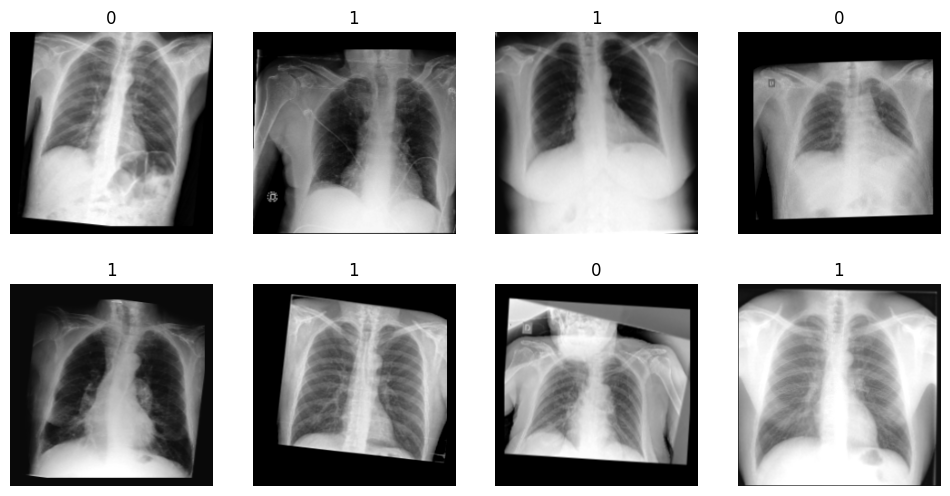

In [ ]:
#STEP4
from google.colab import drive
drive.mount('/content/drive')

import zipfile, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers

SEED = 42

ZIP  = "/content/drive/MyDrive/PSUPRProject_2026Sem2/bimcv_xray/modelA_V2_224.zip"
DATA = "/content/modelA__V2_224"                        # unzip to Colab's local disk (much faster than reading from Drive)
zipfile.ZipFile(ZIP).extractall(DATA)

df = pd.read_csv(f"{DATA}/modelA_224_clean_manifest.csv")
df["path"] = DATA + "/" + df["rel_path"]
print(len(df), "images")
print(df.groupby(["split", "class"]).size().unstack())
print(df.groupby("class")["label"].first())         # which class is label 1

IMG, BATCH = 224, 32

def load(path, label):
    x = tf.io.decode_png(tf.io.read_file(path), channels=1)
    x = tf.image.grayscale_to_rgb(x)                  # 3 channels, same as groupmate's make_tensor
    x = tf.cast(x, tf.float32) / 255.0                # 0-1
    return x, tf.cast(label, tf.float32)

# same augmentation as Model B (no horizontal flip)
augment = tf.keras.Sequential([
    layers.RandomRotation(0.02, fill_mode="constant"),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant"),
    layers.RandomZoom(0.1, fill_mode="constant"),
    layers.RandomBrightness(0.1, value_range=(0, 1)),
])

def make_ds(split, training=False):
    d = df[df["split"] == split]
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values))
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.batch(BATCH)
    if training:
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds = make_ds("train", training=True)
val_ds   = make_ds("val")
test_ds  = make_ds("test")

x, y = next(iter(train_ds))
print("batch:", x.shape, "min/max:", float(tf.reduce_min(x)), float(tf.reduce_max(x)))
plt.figure(figsize=(12, 6))
for i in range(8):
    plt.subplot(2, 4, i + 1); plt.imshow(x[i]); plt.title(int(y[i])); plt.axis("off")
plt.show()

In [ ]:
# STEP 1: ResNet50 Model A (input 0-1, backbone preprocessing inside the model)
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

tf.keras.utils.set_random_seed(SEED)

base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False                                   # stage 1: frozen backbone, train the head only

inputs = keras.Input(shape=(224, 224, 3), name="image")  # 0-1 images, same as the fusion script
x = layers.Rescaling(255.0, name="to_0_255")(inputs)     # 0-1 -> 0-255
x = layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0],
                         name="resnet_preprocess")(x)    # = preprocess_input for grey repeated to 3 channels
x = base(x, training=False)                              # keep BatchNorm in inference mode, also when fine-tuning
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dense(128, activation="relu", name="dense")(x)   # 128-d encoder for the fusion MLP
x = layers.Dropout(0.5, name="dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="output")(x)
model_A_resnet = keras.Model(inputs, outputs, name="modelA_resnet50")
model_A_resnet.summary()

# Check 1: in-model preprocessing matches Keras' preprocess_input on a grey image
img = np.repeat(np.random.rand(2, 224, 224, 1).astype("float32"), 3, axis=-1)
ours = keras.Model(inputs, model_A_resnet.get_layer("resnet_preprocess").output)(img).numpy()
print("Preprocessing max diff vs preprocess_input:", np.abs(ours - preprocess_input(img * 255.0)).max())

# Check 2: save, reload and extract 'dense' the way the fusion script does
model_A_resnet.save("resnet_check.keras")
reloaded = keras.models.load_model("resnet_check.keras")
encoder = keras.Model(reloaded.input, reloaded.get_layer("dense").output)
print("Encoder output shape:", encoder(img).shape)       # expect (2, 128)
print("Same prediction after reload:", np.allclose(model_A_resnet(img), reloaded(img), atol=1e-5))

Model: "modelA_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess               │ (None, 224, 224, 3)    │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

Preprocessing max diff vs preprocess_input: 0.0
Encoder output shape: (2, 128)
Same prediction after reload: True


In [ ]:
# STEP 1b: GPU check, seed, class weights (same as custom CNN)
import os
SEED = 42
MODEL_DIR = "/content/drive/MyDrive/PSUPRProject_2026Sem2/models"
os.makedirs(MODEL_DIR, exist_ok=True)

print("GPU:", tf.config.list_physical_devices("GPU"))

tr = df[df["split"] == "train"]["label"]
class_weight = {c: len(tr) / (2 * (tr == c).sum()) for c in (0, 1)}
print("class_weight:", class_weight)

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
class_weight: {0: np.float64(1.163232104121475), 1: np.float64(0.8769419460343418)}


In [ ]:
# STEP 2: ResNet50 Model  (input 0-1, ResNet's own preprocessing inside the model)
from tensorflow import keras
from tensorflow.keras.applications import ResNet50

tf.keras.utils.set_random_seed(SEED)

base = ResNet50(weights="imagenet", include_top=False, input_shape=(224, 224, 3))
base.trainable = False                                   # stage 1: frozen backbone, train only the new head

inputs = keras.Input(shape=(224, 224, 3), name="image")  # 0-1 images, same as the fusion script
x = layers.Rescaling(255.0, name="to_0_255")(inputs)     # 0-1 -> 0-255
x = layers.Normalization(mean=[103.939, 116.779, 123.68], variance=[1.0, 1.0, 1.0],
                         name="resnet_preprocess")(x)    # same as ResNet50 preprocess_input for grey images
x = base(x, training=False)                              # keep BatchNorm frozen, also later when fine-tuning
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dense(128, activation="relu", name="dense")(x)   # 128-d encoder for the fusion MLP
x = layers.Dropout(0.5, name="dropout")(x)
outputs = layers.Dense(1, activation="sigmoid", name="output")(x)
model_R = keras.Model(inputs, outputs, name="modelA_resnet50")
model_R.summary()

enc = keras.Model(model_R.inputs, model_R.get_layer("dense").output)
print("encoder output:", enc.predict(next(iter(val_ds))[0][:2], verbose=0).shape)   # expect (2, 128)

Model: "modelA_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess               │ (None, 224, 224, 3)    │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 262,401 (1.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

encoder output: (2, 128)


Rescaling and Normalization: these are built-in layers that do the same job as ResNet50’s preprocess_input. I didn’t use a Lambda layer because a plain load_model can’t load one, so it would break your groupmate’s script.
training=False: this keeps ResNet’s BatchNorm statistics from ImageNet. On a small dataset like ours, letting them update tends to make val loss jumpy, which is what happened with my custom CNN.

In [ ]:
# STEP 3: stage 1 - frozen backbone, train only the head
CKPT_R = f"{MODEL_DIR}/modelC_resnet50_18oct.keras"

model_R.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])

callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_R, monitor="val_loss", save_best_only=True, mode="min", verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1),
    keras.callbacks.CSVLogger(CKPT_R.replace(".keras", "_stage1_log.csv")),
]

history_R1 = model_R.fit(train_ds, validation_data=val_ds, epochs=20,
                         class_weight=class_weight, callbacks=callbacks)

best_stage1 = min(history_R1.history["val_loss"])
print("best stage-1 val_loss:", round(best_stage1, 4))

Epoch 1/20
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 340ms/step - accuracy: 0.5282 - auc: 0.5330 - loss: 0.8449
Epoch 1: val_loss improved from None to 0.70162, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelC_resnet50_18oct.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelC_resnet50_18oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 49s 511ms/step - accuracy: 0.5333 - auc: 0.5439 - loss: 0.7548 - val_accuracy: 0.5000 - val_auc: 0.6302 - val_loss: 0.7016 - learning_rate: 0.0010
Epoch 2/20
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.5376 - auc: 0.5633 - loss: 0.7019
Epoch 2: val_loss improved from 0.70162 to 0.67107, saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelC_resnet50_18oct.keras

Epoch 2: finished saving model to /content/drive/MyDrive/PSUPRProject_2026Sem2/models/modelC_resnet50_18oct.keras
68/68 ━━━━━━━━━━━━━━━━━━━━ 24s 342ms/step - accuracy: 0.5548 - auc: 0.5762 - loss: 0.6909 - val_accurac

a good start. The best stage-1 val loss is 0.644, below the custom CNN’s ~0.68, and val AUC got to about 0.68 with only the head trained. It’s plateauing, which is expected while the backbone is frozen.

Why only conv5: it’s the last block, the one that learns the most task-specific patterns. Unfreezing all of ResNet on about 2,100 training images would overfit quickly.
Why BatchNorm stays frozen: updating its statistics on small batches of X-rays can wreck the pretrained features. That’s the same val-loss spiking you saw in the custom CNN.
CKPT_R is the same file as in stage 1 (you named it modelC_resnet50_18oct.keras, which is fine). It only gets overwritten if stage 2 beats 0.644.

In [ ]:
# STEP 4: stage 2 - unfreeze the last ResNet block (conv5), keep BatchNorm frozen, low LR
base.trainable = True
for layer in base.layers:
    layer.trainable = (layer.name.startswith("conv5_")
                       and not isinstance(layer, layers.BatchNormalization))
print("trainable backbone layers:", sum(l.trainable for l in base.layers))

model_R.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-5),   # 100x lower than stage 1
                loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])
model_R.summary()                                                       # trainable params should jump to ~15M

callbacks = [
    keras.callbacks.ModelCheckpoint(CKPT_R, monitor="val_loss", save_best_only=True, mode="min",
                                    initial_value_threshold=best_stage1, verbose=1),   # only saves if it beats stage 1
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, mode="min", restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7, verbose=1),
    keras.callbacks.CSVLogger(CKPT_R.replace(".keras", "_stage2_log.csv")),
]

history_R2 = model_R.fit(train_ds, validation_data=val_ds, epochs=25,
                         class_weight=class_weight, callbacks=callbacks)
print("best stage-2 val_loss:", round(min(history_R2.history["val_loss"]), 4),
      "| stage 1 was:", round(best_stage1, 4))

trainable backbone layers: 22


Model: "modelA_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ to_0_255 (Rescaling)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess               │ (None, 224, 224, 3)    │             0 │
│ (Normalization)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,850,113 (90.98 MB)

 Trainable params: 15,215,873 (58.04 MB)

 Non-trainable params: 8,634,240 (32.94 MB)

Epoch 1/25
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step - accuracy: 0.6081 - auc: 0.6531 - loss: 0.6466
Epoch 1: val_loss did not improve from 0.64390
68/68 ━━━━━━━━━━━━━━━━━━━━ 61s 522ms/step - accuracy: 0.5977 - auc: 0.6499 - loss: 0.6509 - val_accuracy: 0.5475 - val_auc: 0.6747 - val_loss: 0.6751 - learning_rate: 1.0000e-05
Epoch 2/25
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 281ms/step - accuracy: 0.6387 - auc: 0.6890 - loss: 0.6256
Epoch 2: val_loss did not improve from 0.64390
68/68 ━━━━━━━━━━━━━━━━━━━━ 21s 308ms/step - accuracy: 0.6354 - auc: 0.6893 - loss: 0.6295 - val_accuracy: 0.5930 - val_auc: 0.6861 - val_loss: 0.6585 - learning_rate: 1.0000e-05
Epoch 3/25
67/68 ━━━━━━━━━━━━━━━━━━━━ 0s 289ms/step - accuracy: 0.6428 - auc: 0.7167 - loss: 0.6146
Epoch 3: val_loss did not improve from 0.64390
68/68 ━━━━━━━━━━━━━━━━━━━━ 22s 314ms/step - accuracy: 0.6457 - auc: 0.7111 - loss: 0.6190 - val_accuracy: 0.5764 - val_auc: 0.6875 - val_loss: 0.6701 - learning_rate: 1.0000e-05
Epoch 4/25
67/68 ━━━━━━━━

Fine-tuning helped. Val loss went down from 0.644 to 0.623 (epoch 10), and val AUC rose to about 0.72. That file is now the saved model. After epoch 10 it starts to overfit: train AUC reaches 0.87 while val AUC sits at 0.70–0.72, so early stopping at that point was the right call.

Step 5: evaluate on the test set at image and patient level, ResNet50 and your custom CNN side by side

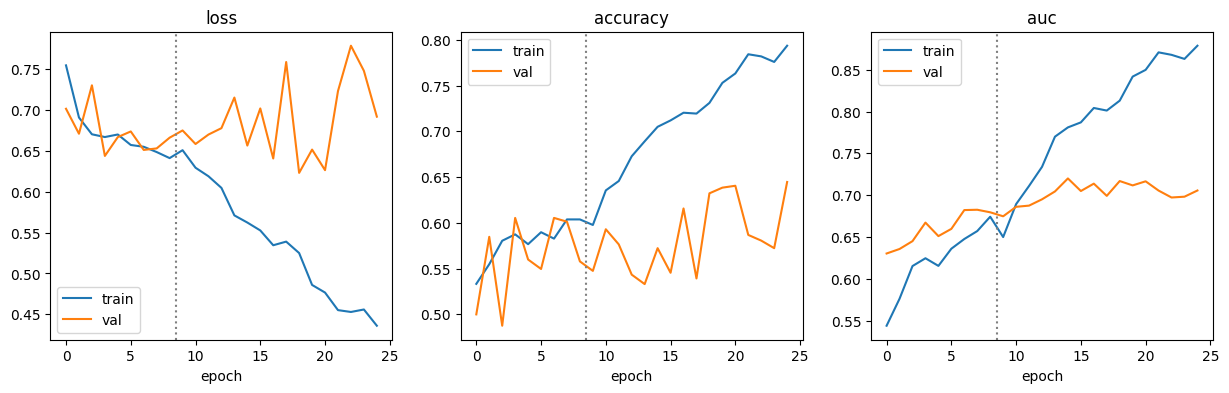

     model   level   n   AUC  accuracy  sensitivity  specificity  TP  FN  TN  FP
  ResNet50   image 436 0.710     0.626        0.556        0.718 138 110 135  53
  ResNet50 patient 282 0.702     0.642        0.562        0.717  77  60 104  41
Custom CNN   image 436 0.649     0.626        0.786        0.415 195  53  78 110
Custom CNN patient 282 0.648     0.560        0.759        0.372 104  33  54  91


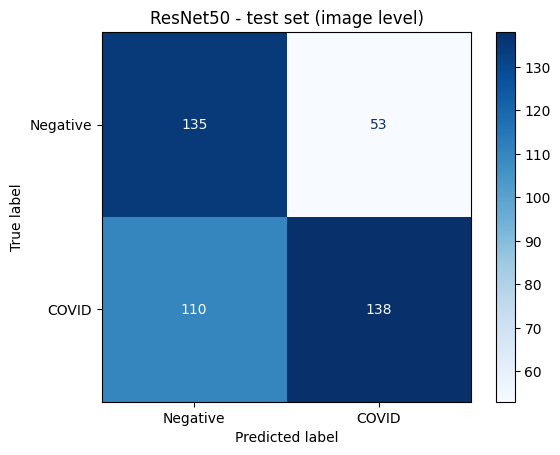

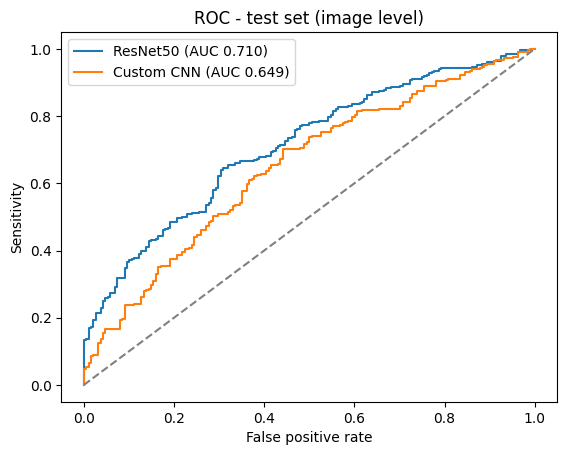

encoder output: (2, 128)


In [ ]:
# STEP 5: test-set evaluation, image level + patient level, ResNet50 vs custom CNN
import numpy as np
from sklearn.metrics import roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay

# training curves, stage 1 + stage 2
s1 = pd.read_csv(CKPT_R.replace(".keras", "_stage1_log.csv"))
s2 = pd.read_csv(CKPT_R.replace(".keras", "_stage2_log.csv"))
log = pd.concat([s1, s2], ignore_index=True)
plt.figure(figsize=(15, 4))
for i, m in enumerate(["loss", "accuracy", "auc"]):
    plt.subplot(1, 3, i + 1)
    plt.plot(log[m], label="train"); plt.plot(log["val_" + m], label="val")
    plt.axvline(len(s1) - 0.5, ls=":", c="grey")              # fine-tuning starts here
    plt.title(m); plt.xlabel("epoch"); plt.legend()
plt.show()

def report(y, p):
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"n": len(y), "AUC": roc_auc_score(y, p), "accuracy": (tp + tn) / len(y),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "TP": tp, "FN": fn, "TN": tn, "FP": fp}

MODELS = {"ResNet50": CKPT_R, "Custom CNN": f"{MODEL_DIR}/model_A_v2_17oct.keras"}
test_df = df[df["split"] == "test"].copy()                    # same order as test_ds (not shuffled)
rows = []
for name, path in MODELS.items():
    m = keras.models.load_model(path)
    test_df[name] = m.predict(test_ds, verbose=0).ravel()
    pat = test_df.groupby("patient_id").agg(label=("label", "first"), prob=(name, "mean"))  # patient = mean of their images
    rows.append({"model": name, "level": "image",   **report(test_df["label"].values, test_df[name].values)})
    rows.append({"model": name, "level": "patient", **report(pat["label"].values, pat["prob"].values)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ResNet50 confusion matrix (image level) + ROC of both models
ConfusionMatrixDisplay(confusion_matrix(test_df["label"], (test_df["ResNet50"] >= 0.5).astype(int)),
                       display_labels=["Negative", "COVID"]).plot(cmap="Blues")
plt.title("ResNet50 - test set (image level)"); plt.show()
for name in MODELS:
    fpr, tpr, _ = roc_curve(test_df["label"], test_df[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(test_df['label'], test_df[name]):.3f})")
plt.plot([0, 1], [0, 1], "--", c="grey"); plt.xlabel("False positive rate"); plt.ylabel("Sensitivity")
plt.title("ROC - test set (image level)"); plt.legend(); plt.show()

# fusion check on the saved ResNet file
best_R = keras.models.load_model(CKPT_R)
enc = keras.Model(best_R.inputs, best_R.get_layer("dense").output)
print("encoder output:", enc.predict(next(iter(test_ds))[0][:2], verbose=0).shape)   # expect (2, 128)

ResNet50 does better than the custom CNN on the same test set. AUC is 0.71 vs 0.65 at image level and 0.70 vs 0.65 at patient level. AUC is the fairest comparison here, because it doesn’t depend on the 0.5 cut-off.

At the 0.5 threshold the two models trade off differently. Image-level accuracy is the same (0.626).

ResNet50 is cautious about calling COVID. Sensitivity is 0.56 and specificity 0.72, so it misses 110 of 248 COVID images.
Custom CNN calls COVID too often. Sensitivity is 0.79, but specificity is only 0.42, so it wrongly flags 110 of 188 Negatives.
With both classes weighted equally (balanced accuracy), ResNet50 scores 0.64 and the custom CNN 0.60.

Patient level (282 patients) gives the same picture. ResNet50’s accuracy rises to 0.64. The custom CNN’s drops to 0.56, because averaging a patient’s images doesn’t fix its tendency to say COVID.

For your report: ImageNet pretraining added about 0.06 AUC, but both models end up at 0.65–0.71. That suggests this BIMCV data is hard to separate on frontal X-rays alone, which is a useful finding in itself.

     model   level   thr   n   AUC  accuracy  sensitivity  specificity  bal_acc  TP  FN  TN  FP
  ResNet50   image 0.464 436 0.710     0.665        0.641        0.697    0.669 159  89 131  57
  ResNet50 patient 0.444 282 0.702     0.652        0.672        0.634    0.653  92  45  92  53
Custom CNN   image 0.585 436 0.649     0.557        0.355        0.824    0.590  88 160 155  33
Custom CNN patient 0.561 282 0.648     0.606        0.438        0.766    0.602  60  77 111  34


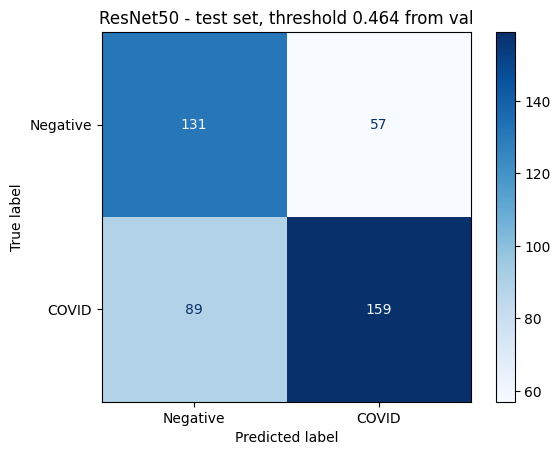

In [ ]:
# STEP 6: threshold chosen on VALIDATION (Youden's J = max sensitivity + specificity - 1), applied once to test
def report(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"thr": thr, "n": len(y), "AUC": roc_auc_score(y, p), "accuracy": (tp + tn) / len(y),
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "bal_acc": (tp / (tp + fn) + tn / (tn + fp)) / 2, "TP": tp, "FN": fn, "TN": tn, "FP": fp}

def youden(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr - fpr)])

def level_view(d, name, level):        # image rows as they are, or one row per patient (mean probability)
    if level == "image":
        return d["label"].values, d[name].values
    g = d.groupby("patient_id").agg(label=("label", "first"), prob=(name, "mean"))
    return g["label"].values, g["prob"].values

val_df = df[df["split"] == "val"].copy()          # same order as val_ds (not shuffled)
rows = []
for name, path in MODELS.items():
    val_df[name] = keras.models.load_model(path).predict(val_ds, verbose=0).ravel()
    for level in ["image", "patient"]:
        thr = youden(*level_view(val_df, name, level))                       # chosen on val only
        rows.append({"model": name, "level": level, **report(*level_view(test_df, name, level), thr)})
print(pd.DataFrame(rows).round(3).to_string(index=False))

thr_R = rows[0]["thr"]                            # ResNet50, image level
ConfusionMatrixDisplay(confusion_matrix(test_df["label"], (test_df["ResNet50"] >= thr_R).astype(int)),
                       display_labels=["Negative", "COVID"]).plot(cmap="Blues")
plt.title(f"ResNet50 - test set, threshold {thr_R:.3f} from val"); plt.show()

The val-chosen threshold makes ResNet50 more balanced, and it still beats the custom CNN.

ResNet50: accuracy goes from 0.626 to 0.665. It now catches 159 of 248 COVID images, up from 138, while still keeping 131 of 188 Negatives correct. Its val thresholds (0.46 and 0.44) sit close to 0.5, so its probabilities carry over well from val to test.
Custom CNN: the threshold chosen on val swings it the other way, to sensitivity 0.36 and specificity 0.82. So its scores are less stable between val and test, which fits it being the weaker model.

Model C (ResNet50, ImageNet-pretrained, fine-tuned conv5): test set of 436 images / 282 patients

AUC 0.710 per image and 0.702 per patient (custom CNN 0.649 / 0.648; EfficientNetB0 0.670 / 0.619)
At the val-chosen threshold of 0.464 (image level): accuracy 0.665, sensitivity 0.641 (159 of 248 COVID), specificity 0.697 (131 of 188 Negative), balanced accuracy 0.669
At patient level (mean probability per patient, threshold 0.444): accuracy 0.652, sensitivity 0.672, specificity 0.634
It was the best of the three models and the most balanced. The custom CNN either over-calls or under-calls COVID depending on the threshold.
The encoder (layer dense, 128-dim) loads with plain load_model, so it’s ready for fusion.

why the threshold isn’t 0.5: it was picked on validation data only (Youden’s J), so the test set